## Convert NPY Files Back to LAS Format

Convert ForestFormer NPY outputs back to LAS for visualization and validation.## Setup and Imports

In [60]:
# Title: Setup — Paths & output directories

import os
import sys
from pathlib import Path
import laspy
import numpy as np
import pandas as pd
from pyntcloud import PyntCloud
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# PATHS (edit these or override via env vars)
# -----------------------------------------------------------------------------
# You can override any of these with environment variables, e.g.:
#   export FVC_DATA_ROOT=/my/data/root
#   export FVC_INPUT_LAS_DIR=/my/original/las
#   export FVC_INPUT_PLY_DIR=/my/ply
#   export FVC_INPUT_NPY_DIR=/my/npy
#   export FVC_OUT_NPY_LAS_DIR=/my/out/npy_las
#   export FVC_OUT_PLY_LAS_DIR=/my/out/ply_las

DATA_ROOT = Path(os.environ.get("FVC_DATA_ROOT", "/data/calperumResearch/site1_1_DD0001/lidar/clipped")).expanduser()

# Original labeled LAS directory (structure + treeID)
INPUT_LAS_DIR = Path(os.environ.get("FVC_INPUT_LAS_DIR", str(DATA_ROOT / "3d_structure_mask_malleid"))).expanduser()

# Preprocessed inputs
INPUT_PLY_DIR = Path(os.environ.get("FVC_INPUT_PLY_DIR", str(DATA_ROOT / "preprocessed/forestformer3d_ply"))).expanduser()
INPUT_NPY_DIR = Path(os.environ.get("FVC_INPUT_NPY_DIR", str(DATA_ROOT / "preprocessed/forestformer3d_npy"))).expanduser()

# Outputs
OUT_PLY_LAS_DIR = Path(os.environ.get("FVC_OUT_PLY_LAS_DIR", str(DATA_ROOT / "preprocessed/reconstructed_forestformer_ply_las"))).expanduser()
OUT_NPY_LAS_DIR = Path(os.environ.get("FVC_OUT_NPY_LAS_DIR", str(DATA_ROOT / "preprocessed/reconstructed_forestformer_npy_las"))).expanduser()

# Backward-compat aliases used later in this notebook
INPUT_DIR = INPUT_LAS_DIR
OUT_PLY_DIR = INPUT_PLY_DIR
OUT_LAS_DIR = OUT_NPY_LAS_DIR

# Create only output dirs (inputs should already exist)
OUT_PLY_LAS_DIR.mkdir(parents=True, exist_ok=True)
OUT_NPY_LAS_DIR.mkdir(parents=True, exist_ok=True)

print(f"📂 DATA_ROOT:         {DATA_ROOT}")
print(f"📂 Input LAS (orig):  {INPUT_LAS_DIR}")
print(f"📂 Input PLY:         {INPUT_PLY_DIR}")
print(f"📂 Input NPY:         {INPUT_NPY_DIR}")
print(f"📂 Output LAS (PLY):  {OUT_PLY_LAS_DIR}")
print(f"📂 Output LAS (NPY):  {OUT_NPY_LAS_DIR}")

📂 DATA_ROOT:         /data/calperumResearch/site1_1_DD0001/lidar/clipped
📂 Input LAS (orig):  /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid
📂 Input PLY:         /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply
📂 Input NPY:         /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_npy
📂 Output LAS (PLY):  /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_ply_las
📂 Output LAS (NPY):  /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_npy_las


In [ ]:
# Title: Setup — Imports & project root

import sys
from pathlib import Path

# Add parent directory to path for imports
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import laspy
import numpy as np
import pandas as pd
from pyntcloud import PyntCloud
import matplotlib.pyplot as plt

print(f"✅ Project root: {PROJECT_ROOT}")
print(f"✅ All imports successful")

✅ Project root: /home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training
✅ All imports successful


In [ ]:
# Title: ForestFormer — Export PLY → NPY (+ offsets/CRS)

import datetime
import os
import sys
from os import path as osp

# Add forestformer_preprocessing to path
sys.path.insert(0, str(PROJECT_ROOT / "forestformer_preprocessing"))

# Create plyutils module inline since it's not in the repo
import importlib.util
spec = importlib.util.spec_from_loader("plyutils", loader=None)
plyutils = importlib.util.module_from_spec(spec)

def read_ply(filename):
    """Read PLY file using PyntCloud"""
    cloud = PyntCloud.from_file(str(filename))
    points_df = cloud.points
    
    # Print format information
    print(f"  PLY columns: {list(points_df.columns)}")
    print(f"  PLY shape: {points_df.shape}")
    
    # Convert to dictionary format expected by load_forainetv2_data
    result = {}
    for col in points_df.columns:
        result[col] = points_df[col].values
    return result

plyutils.read_ply = read_ply
sys.modules['plyutils'] = plyutils

# Now import the export function from load_forainetv2_data
from load_forainetv2_data import export

DONOTCARE_CLASS_IDS = np.array([])
FORAINETV2_OBJ_CLASS_IDS = np.array([1])


def guess_original_las(stem: str, input_las_dir: Path | None = None):
    """Heuristic to map processed scan names back to original LAS/LAZ filenames."""
    search_dir = Path(input_las_dir) if input_las_dir is not None else INPUT_LAS_DIR
    variants = set()
    variants.add(stem)
    variants.add(stem.replace("_from_ply", ""))
    variants.add(stem.replace("_from_npy", ""))
    variants.add(stem.replace("_from_npz", ""))
    variants.add(stem.replace("_knnclustering", ""))
    variants.add(stem.replace("_forest", ""))
    for variant in variants:
        variant = variant.strip()
        if not variant:
            continue
        for ext in (".las", ".laz"):
            candidate = search_dir / f"{variant}{ext}"
            if candidate.exists():
                return candidate
    return None


def export_one_scan_forestformer(scan_name, output_filename_prefix, max_num_point, ply_dir, test_mode=False):
    """
    Export one PLY scan to NPZ format using ForestFormer's export function.
    
    IMPORTANT: Combines preprocessing offset (LAS→PLY) with ForestFormer recentering offset
    to enable full reconstruction back to original LAS global coordinates.
    """
    ply_file = osp.join(ply_dir, scan_name + '.ply')
    
    # Read original LAS file to get CRS and header information
    original_las_path = guess_original_las(scan_name, input_las_dir=INPUT_LAS_DIR)
    crs_info = None
    original_las = None
    if original_las_path is not None:
        try:
            original_las = laspy.read(str(original_las_path))
            header_offsets = np.array(original_las.header.offsets, dtype=np.float64)
            header_scales = np.array(original_las.header.scales, dtype=np.float64)
            
            # Try to get CRS as WKT string for serialization
            crs_wkt = None
            try:
                crs_obj = original_las.header.parse_crs()
                if crs_obj is not None:
                    crs_wkt = crs_obj.to_wkt() if hasattr(crs_obj, 'to_wkt') else str(crs_obj)
            except Exception:
                pass
            
            crs_info = {
                'crs_wkt': crs_wkt,  # CRS as WKT string (serializable)
                'has_vlrs': len(original_las.header.vlrs) > 0,  # Flag if VLRs present
                'header_offset': header_offsets,
                'header_scale': header_scales,
                # Backward-compatible keys
                'offsets': header_offsets,
                'scales': header_scales,
            }
            print(f"  Preserved CRS from original LAS: {original_las_path.name}")
            if crs_wkt:
                print(f"    CRS: {crs_wkt[:80]}..." if len(crs_wkt) > 80 else f"    CRS: {crs_wkt}")
        except Exception as e:
            print(f"  Warning: Could not read CRS from original LAS {original_las_path}: {e}")
    else:
        print(f"  ⚠️ Could not locate original LAS for {scan_name}")
    
    # Use the export function from load_forainetv2_data
    mesh_vertices, semantic_labels, instance_labels, unaligned_bboxes, \
        aligned_bboxes, axis_align_matrix, offsets = export(ply_file, None, test_mode)
    
    # Load intensity values from PLY before any filtering (to preserve original values)
    intensity_values = None
    try:
        ply_cloud_data = PyntCloud.from_file(str(ply_file))
        if 'intensity' in ply_cloud_data.points.columns:
            # Keep original raw intensity values as float32
            intensity_values = ply_cloud_data.points['intensity'].values.astype(np.float32).copy()
            print(f"  Loaded intensity from PLY: range [{intensity_values.min():.2f}, {intensity_values.max():.2f}]")
    except Exception as e:
        print(f"  ⚠️ Could not load intensity from PLY: {e}")
    
    # CRITICAL: Load preprocessing offset (LAS→PLY) and combine with ForestFormer offset
    preprocessing_offset_file = Path(ply_dir) / f"{scan_name}_offset.npy"
    if preprocessing_offset_file.exists():
        preprocessing_offset = np.load(str(preprocessing_offset_file))
        combined_offset = preprocessing_offset + offsets
        print(f"  Loaded preprocessing offset: {preprocessing_offset}")
        print(f"  ForestFormer recentering offset: {offsets}")
        print(f"  Combined offset (for LAS reconstruction): {combined_offset}")
        offsets = combined_offset  # Use combined offset
    else:
        print(f"  ⚠️ Warning: Preprocessing offset sidecar not found ({preprocessing_offset_file.name})")
        print(f"     Using ForestFormer offset only - LAS reconstruction will be in local coords")
    
    if not test_mode:
        # Filter out "do not care" classes
        mask = np.logical_not(np.in1d(semantic_labels, DONOTCARE_CLASS_IDS))
        mesh_vertices = mesh_vertices[mask, :]
        semantic_labels = semantic_labels[mask]
        instance_labels = instance_labels[mask]
        
        # Also filter intensity if it was loaded
        if intensity_values is not None:
            intensity_values = intensity_values[mask]
        
        num_instances = len(np.unique(instance_labels[instance_labels > 0]))
        print(f'  Num of instances: {num_instances}')
        
        # Filter bounding boxes by class
        OBJ_CLASS_IDS = FORAINETV2_OBJ_CLASS_IDS
        bbox_mask = np.in1d(unaligned_bboxes[:, -1], OBJ_CLASS_IDS)
        unaligned_bboxes = unaligned_bboxes[bbox_mask, :]
        bbox_mask = np.in1d(aligned_bboxes[:, -1], OBJ_CLASS_IDS)
        aligned_bboxes = aligned_bboxes[bbox_mask, :]
        print(f'  Num of care instances: {unaligned_bboxes.shape[0]}')
    
    # Downsample if needed
    if max_num_point is not None:
        max_num_point = int(max_num_point)
        N = mesh_vertices.shape[0]
        if N > max_num_point:
            choices = np.random.choice(N, max_num_point, replace=False)
            mesh_vertices = mesh_vertices[choices, :]
            if not test_mode:
                semantic_labels = semantic_labels[choices]
                instance_labels = instance_labels[choices]
            # Also downsample intensity
            if intensity_values is not None:
                intensity_values = intensity_values[choices]
    
    # Calculate z_norm (normalized height above ground)
    z_norm = mesh_vertices[:, 2] - mesh_vertices[:, 2].min()
    
    # Save all arrays
    np.save(f'{output_filename_prefix}_vert.npy', mesh_vertices)
    np.save(f'{output_filename_prefix}_offsets.npy', offsets)  # Now contains combined offset
    np.save(f'{output_filename_prefix}_z_norm.npy', z_norm.astype(np.float32))
    print(f"  ✓ Saved z_norm (height above ground): range [{z_norm.min():.2f}, {z_norm.max():.2f}]")
    
    # Save intensity values if they were loaded
    if intensity_values is not None:
        np.save(f'{output_filename_prefix}_intensity.npy', intensity_values)
        print(f"  ✓ Saved intensity values")
    
    if not test_mode:
        np.save(f'{output_filename_prefix}_sem_label.npy', semantic_labels)
        np.save(f'{output_filename_prefix}_ins_label.npy', instance_labels)
        np.save(f'{output_filename_prefix}_unaligned_bbox.npy', unaligned_bboxes)
        np.save(f'{output_filename_prefix}_aligned_bbox.npy', aligned_bboxes)
        np.save(f'{output_filename_prefix}_axis_align_matrix.npy', axis_align_matrix)
    
    # Save CRS/header information sidecar if available
    if crs_info is not None:
        np.savez(
            f'{output_filename_prefix}_crs.npz',
            crs_wkt=np.array([crs_info['crs_wkt']]) if crs_info['crs_wkt'] else np.array([]),
            has_vlrs=crs_info['has_vlrs'],
            header_offset=crs_info['header_offset'],
            header_scale=crs_info['header_scale'],
            offsets=crs_info['offsets'],
            scales=crs_info['scales'],
        )
        print(f"  ✓ Saved CRS information")
        
        # Also save original LAS path reference for VLR copying during reconstruction
        if original_las is not None:
            try:
                with open(f'{output_filename_prefix}_original_las_path.txt', 'w') as f:
                    f.write(str(original_las_path))
                print(f"  ✓ Saved original LAS path reference")
            except Exception as e:
                print(f"  ⚠️ Could not save original LAS path: {e}")


def batch_export_ply_to_npz(ply_dir, output_folder, max_num_point=None, test_mode=False, max_files=None):
    """Batch export PLY files to NPZ format using ForestFormer preprocessing."""
    if not os.path.exists(output_folder):
        print(f'Creating new data folder: {output_folder}')
        os.makedirs(output_folder, exist_ok=True)
    
    ply_files = sorted(Path(ply_dir).glob("*.ply"))
    if max_files:
        ply_files = ply_files[:max_files]
    
    print(f"Found {len(ply_files)} PLY files to process")
    for i, ply_file in enumerate(ply_files, 1):
        scan_name = ply_file.stem
        print(f"\n[{i}/{len(ply_files)}] {'-' * 20} begin")
        print(f'{datetime.datetime.now()}')
        print(f'Processing: {scan_name}')
        
        output_filename_prefix = osp.join(output_folder, scan_name)
        if osp.isfile(f'{output_filename_prefix}_vert.npy'):
            print('File already exists. skipping.')
            print('-' * 20 + 'done')
            continue
        
        try:
            export_one_scan_forestformer(scan_name, output_filename_prefix, max_num_point, ply_dir, test_mode)
            print(f'  ✓ Saved to {scan_name}_*.npy')
        except Exception as e:
            print(f'  ✗ Failed export scan: {scan_name}')
            print(f'  Error: {e}')
            import traceback
            traceback.print_exc()
        
        print('-' * 20 + 'done')
    
    print(f"\n✅ Batch PLY to NPZ conversion complete!")


# Run batch conversion from PLY to NPZ (uncomment to run)
# batch_export_ply_to_npz(
#     ply_dir=str(INPUT_PLY_DIR),
#     output_folder=str(INPUT_NPY_DIR),
#     max_num_point=None,
#     test_mode=False,
#     max_files=None,
# )

In [ ]:
# Title: Convert — NPY → LAS

def npy_to_las(npy_prefix, out_las_path, original_las_path=None):
    """Convert ForestFormer NPY files back to LAS format with original CRS.
    
    Args:
        npy_prefix: Path prefix for NPY files (e.g., /path/to/scan_name)
        out_las_path: Output LAS path
        original_las_path: Optional path to original LAS to preserve CRS and header
    """
    npy_prefix = Path(npy_prefix)
    out_las_path = Path(out_las_path)
    
    print(f"Converting {npy_prefix.name} → {out_las_path.name}")
    
    # Load NPY data from separate files
    vertices = np.load(str(npy_prefix.parent / f"{npy_prefix.name}_vert.npy"))
    offsets = np.load(str(npy_prefix.parent / f"{npy_prefix.name}_offsets.npy"))
    sem_labels = np.load(str(npy_prefix.parent / f"{npy_prefix.name}_sem_label.npy"))
    ins_labels = np.load(str(npy_prefix.parent / f"{npy_prefix.name}_ins_label.npy"))

    
    print(f"  Loaded {len(vertices):,} points")
    print(f"  Local coords range: [{vertices.min(axis=0)}, {vertices.max(axis=0)}]")
    print(f"  Offset (global origin): {offsets}")
    
    # Load CRS sidecar if available
    crs_sidecar = npy_prefix.parent / f"{npy_prefix.name}_crs.npz"
    crs_info = None
    saved_original_las_path = None
    
    if crs_sidecar.exists():
        crs_data = np.load(str(crs_sidecar), allow_pickle=True)
        crs_wkt = None
        if 'crs_wkt' in crs_data and len(crs_data['crs_wkt']) > 0:
            crs_wkt = str(crs_data['crs_wkt'][0])
        
        crs_info = {
            'crs_wkt': crs_wkt,
            'has_vlrs': bool(crs_data['has_vlrs']) if 'has_vlrs' in crs_data else False,
            'header_offset': crs_data['header_offset'] if 'header_offset' in crs_data else None,
            'header_scale': crs_data['header_scale'] if 'header_scale' in crs_data else None,
        }
        print(f"  ✓ Loaded CRS sidecar")
    
    # Check for original LAS path reference (for VLR copying)
    orig_las_ref = npy_prefix.parent / f"{npy_prefix.name}_original_las_path.txt"
    if orig_las_ref.exists():
        try:
            with open(str(orig_las_ref), 'r') as f:
                saved_original_las_path = Path(f.read().strip())
            if saved_original_las_path.exists():
                print(f"  ✓ Found original LAS reference: {saved_original_las_path.name}")
        except Exception as e:
            print(f"  ⚠️ Could not read original LAS reference: {e}")
    
    # Try to get original LAS for header and CRS (prefer saved reference, then parameter)
    use_original_header = False
    original_las = None
    
    # Prioritize saved original LAS path reference
    las_to_use = saved_original_las_path if saved_original_las_path and saved_original_las_path.exists() else original_las_path
    
    # Reconstruct absolute coordinates first (needed for fallback offset calculation)
    xyz_abs = vertices + offsets
    
    if las_to_use and Path(las_to_use).exists():
        original_las = laspy.read(str(las_to_use))
        header_offset = np.array(original_las.header.offsets, dtype=np.float64)
        header_scale = np.array(original_las.header.scales, dtype=np.float64)
        print(f"  Using original header from {Path(las_to_use).name}")
        use_original_header = True
    elif crs_info and crs_info['header_offset'] is not None:
        header_offset = crs_info['header_offset']
        header_scale = crs_info['header_scale']
        print(f"  Using saved header: offset={header_offset}, scale={header_scale}")
    else:
        # Fallback: compute from data
        header_offset = xyz_abs.min(axis=0)
        header_scale = np.array([0.001, 0.001, 0.001])
        print(f"  ⚠️ No original header found, using computed offset")
    
    print(f"  Global coords range: [{xyz_abs.min(axis=0)}, {xyz_abs.max(axis=0)}]")
    
    # Create LAS header with offset and scale
    header = laspy.LasHeader(version="1.4", point_format=6)
    header.offsets = header_offset
    header.scales = header_scale
    
    # Copy CRS from original if available (VLRs are the most reliable method)
    if use_original_header and original_las:
        # Copy VLRs (Variable Length Records) which contain CRS info
        for vlr in original_las.header.vlrs:
            header.vlrs.append(vlr)
        print(f"  ✅ Copied {len(original_las.header.vlrs)} VLRs (including CRS)")
    elif crs_info and crs_info.get('crs_wkt'):
        # Fallback: try to reconstruct CRS from WKT string
        try:
            from pyproj import CRS
            crs_obj = CRS.from_wkt(crs_info['crs_wkt'])
            header.add_crs(crs_obj)
            print(f"  ✅ Attached CRS from WKT sidecar")
        except Exception as e:
            print(f"  ⚠️ Could not attach CRS from WKT: {e}")
            print(f"     (This is OK if original LAS has VLRs that were copied)")
    
    # Add extra dimensions
    # Note: Using 'intensity_norm' since 'intensity' conflicts with built-in LAS field
    intensity_extra_bytes = laspy.ExtraBytesParams(name="intensity_norm", type="f4", description="Intensity from PLY (float32)")
    header.add_extra_dim(intensity_extra_bytes)
    
    z_norm_extra_bytes = laspy.ExtraBytesParams(name="z_norm", type="f4", description="Normalized height (m)")
    header.add_extra_dim(z_norm_extra_bytes)
    
    # Create LAS data
    las = laspy.LasData(header)
    
    # Set coordinates (will use header offset/scale)
    las.x = xyz_abs[:, 0]
    las.y = xyz_abs[:, 1]
    las.z = xyz_abs[:, 2]
    
    # Set classification to 0 (unclassified) as default
    las.classification = np.zeros(len(vertices), dtype=np.uint8)
    
    # Load intensity - first try saved intensity file, then fall back to PLY
    intensity_file = npy_prefix.parent / f"{npy_prefix.name}_intensity.npy"
    
    if intensity_file.exists():
        try:
            intensity_values = np.load(str(intensity_file))
            if len(intensity_values) == len(vertices):
                # Set intensity as float32 in extra dimension (keep original values, no scaling)
                las['intensity_norm'] = intensity_values.astype(np.float32)
                print(f"  ✓ Loaded intensity from saved file: range [{intensity_values.min():.2f}, {intensity_values.max():.2f}]")
            else:
                print(f"  ⚠️ Intensity file point count mismatch, using default")
                las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
        except Exception as e:
            las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
    else:
        # Fallback: try to load from original PLY file
        try:
            ply_path = Path(str(npy_prefix.parent).replace('forestformer3d_npz', 'forestformer3d_ply')) / f"{npy_prefix.name}.ply"
            
            if ply_path.exists():
                from pyntcloud import PyntCloud
                ply_cloud = PyntCloud.from_file(str(ply_path))
                
                if 'intensity' in ply_cloud.points.columns:
                    ply_intensity = ply_cloud.points['intensity'].values
                    
                    if len(ply_intensity) == len(vertices):
                        # Keep original float32 values (no scaling)
                        las['intensity_norm'] = ply_intensity.astype(np.float32)
                        print(f"  ✓ Loaded intensity from PLY: range [{ply_intensity.min():.2f}, {ply_intensity.max():.2f}]")
                    else:
                        print(f"  ⚠️ PLY point count mismatch ({len(ply_intensity)} vs {len(vertices)}), using default")
                        las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
                else:
                    print(f"  ⚠️ No intensity column in PLY, using default")
                    las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
            else:
                print(f"  ⚠️ PLY file not found, using default intensity")
                las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
        except Exception as e:
            print(f"  ⚠️ Could not load intensity from PLY: {e}, using default")
            las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
    
    # Load z_norm (normalized height)
    z_norm_file = npy_prefix.parent / f"{npy_prefix.name}_z_norm.npy"
    if z_norm_file.exists():
        try:
            z_norm_values = np.load(str(z_norm_file))
            if len(z_norm_values) == len(vertices):
                las['z_norm'] = z_norm_values.astype(np.float32)
                print(f"  ✓ Loaded z_norm: range [{z_norm_values.min():.2f}, {z_norm_values.max():.2f}] m")
            else:
                print(f"  ⚠️ z_norm file point count mismatch, using computed values")
                las['z_norm'] = (vertices[:, 2] - vertices[:, 2].min()).astype(np.float32)
        except Exception as e:
            print(f"  ⚠️ Could not load z_norm: {e}, computing from vertices")
            las['z_norm'] = (vertices[:, 2] - vertices[:, 2].min()).astype(np.float32)
    else:
        # Compute z_norm if not saved
        las['z_norm'] = (vertices[:, 2] - vertices[:, 2].min()).astype(np.float32)
        print(f"  ℹ️ Computed z_norm from vertices: range [{las['z_norm'].min():.2f}, {las['z_norm'].max():.2f}] m")
    
    # Add extra dimensions for semantic and instance labels (matching PLY naming convention)
    las.add_extra_dim(laspy.ExtraBytesParams(name="semantic_seg", type=np.int32))
    las.add_extra_dim(laspy.ExtraBytesParams(name="treeID", type=np.int32))
    
    las["semantic_seg"] = sem_labels.astype(np.int32)
    las["treeID"] = ins_labels.astype(np.int32)
    
    # Write LAS file
    las.write(str(out_las_path))
    print(f"✅ Saved: {out_las_path}")
    return out_las_path

def batch_npy_to_las(npy_folder, output_las_folder, original_las_folder=None, max_files=None):
    """Batch convert ForestFormer NPY files to LAS format.
    
    Args:
        npy_folder: Folder containing NPY files
        output_las_folder: Output folder for LAS files
        original_las_folder: Optional folder with original LAS files for CRS
        max_files: Optional limit on number of files to convert
    """
    npy_folder = Path(npy_folder)
    output_las_folder = Path(output_las_folder)
    output_las_folder.mkdir(parents=True, exist_ok=True)
    
    # Find all _vert.npy files (one per scan)
    vert_files = sorted(npy_folder.glob("*_vert.npy"))
    
    if max_files:
        vert_files = vert_files[:max_files]
    
    print(f"\n🔄 Converting {len(vert_files)} NPY sets to LAS format...")
    
    for i, vert_file in enumerate(vert_files, 1):
        # Extract scan name (remove _vert.npy suffix)
        scan_name = vert_file.stem.replace("_vert", "")
        
        print(f"\n[{i}/{len(vert_files)}] Processing: {scan_name}")
        
        # Build paths
        npy_prefix = npy_folder / scan_name
        out_las = output_las_folder / f"{scan_name}_from_npy.las"
        
        # Try to find original LAS
        orig_las = None
        if original_las_folder:
            orig_las = guess_original_las(scan_name, input_las_dir=original_las_folder)
            if orig_las and not orig_las.exists():
                orig_las = None
        
        # Convert
        try:
            npy_to_las(npy_prefix, out_las, original_las_path=orig_las)
        except Exception as e:
            print(f"  ✗ Failed: {e}")
            import traceback
            traceback.print_exc()
    
    print(f"\n✅ Batch conversion complete!")

In [ ]:
# Title: Run — Convert a sample NPY → LAS

# Convert one sample NPY to LAS
sample_files = sorted(INPUT_NPY_DIR.glob("*_vert.npy"))

if sample_files:
    sample_vert = sample_files[0]
    scan_name = sample_vert.stem.replace("_vert", "")
    
    print(f"Converting sample: {scan_name}\n")
    
    npy_prefix = INPUT_NPY_DIR / scan_name
    out_las = OUT_NPY_LAS_DIR / f"{scan_name}_from_npy.las"
    orig_las = guess_original_las(scan_name, input_las_dir=INPUT_LAS_DIR)
    
    print(f"NPY prefix: {npy_prefix}")
    print(f"Output LAS: {out_las}")
    print(f"Original LAS: {orig_las if orig_las and orig_las.exists() else 'Not found'}\n")
    
    npy_to_las(npy_prefix, out_las, original_las_path=orig_las if orig_las and orig_las.exists() else None)
else:
    print("❌ No NPY files found. Run the export cell first.")

Converting sample: znorm_3Dlabels_106

NPY prefix: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_npy/znorm_3Dlabels_106
Output LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_npy_las/znorm_3Dlabels_106_from_npy.las
Original LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las

Converting znorm_3Dlabels_106 → znorm_3Dlabels_106_from_npy.las
  Loaded 265,746 points
  Local coords range: [[-17.528542 -15.812152   0.      ], [13.171459 14.887849  4.92    ]]
  Offset (global origin): [4.61696999e+05 6.23752201e+06 5.78300000e+01]
  ✓ Loaded CRS sidecar
  ✓ Found original LAS reference: znorm_3Dlabels_106.las
  Using original header from znorm_3Dlabels_106.las
  Global coords range: [[4.6167947e+05 6.2375062e+06 5.7830000e+01], [4.61710170e+05 6.23753690e+06 6.27500001e+01]]
  ✅ Copied 3 VLRs (including CRS)
  ✓ Loaded intensity from saved file: range [0.00,

In [ ]:
# Title: Run — Batch NPY → LAS

# Batch convert all NPY files to LAS (uncomment to run)
batch_npy_to_las(
    npy_folder=INPUT_NPY_DIR,
    output_las_folder=OUT_NPY_LAS_DIR,
    original_las_folder=INPUT_LAS_DIR,
    max_files=None  # Set to limit number of files
)


🔄 Converting 15 NPY sets to LAS format...

[1/15] Processing: znorm_3Dlabels_106
Converting znorm_3Dlabels_106 → znorm_3Dlabels_106_from_npy.las
  Loaded 265,746 points
  Local coords range: [[-17.528542 -15.812152   0.      ], [13.171459 14.887849  4.92    ]]
  Offset (global origin): [4.61696999e+05 6.23752201e+06 5.78300000e+01]
  ✓ Loaded CRS sidecar
  ✓ Found original LAS reference: znorm_3Dlabels_106.las
  Using original header from znorm_3Dlabels_106.las
  Global coords range: [[4.6167947e+05 6.2375062e+06 5.7830000e+01], [4.61710170e+05 6.23753690e+06 6.27500001e+01]]
  ✅ Copied 3 VLRs (including CRS)
  ✓ Loaded intensity from saved file: range [0.00, 0.42]
  ✓ Loaded z_norm: range [0.00, 4.92] m
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_npy_las/znorm_3Dlabels_106_from_npy.las

[2/15] Processing: znorm_3Dlabels_109
Converting znorm_3Dlabels_109 → znorm_3Dlabels_109_from_npy.las
  Loaded 394,473 points


  Local coords range: [[-15.158568 -15.177109   0.      ], [15.551431 15.522892  5.64    ]]
  Offset (global origin): [4.61786679e+05 6.23752132e+06 5.94300000e+01]
  ✓ Loaded CRS sidecar
  ✓ Found original LAS reference: znorm_3Dlabels_109.las
  Using original header from znorm_3Dlabels_109.las
  Global coords range: [[4.61771520e+05 6.23750614e+06 5.94300000e+01], [4.61802230e+05 6.23753684e+06 6.50699999e+01]]
  ✅ Copied 3 VLRs (including CRS)
  ✓ Loaded intensity from saved file: range [0.00, 0.41]
  ✓ Loaded z_norm: range [0.00, 5.64] m
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_npy_las/znorm_3Dlabels_109_from_npy.las

[3/15] Processing: znorm_3Dlabels_113
Converting znorm_3Dlabels_113 → znorm_3Dlabels_113_from_npy.las
  Loaded 417,671 points
  Local coords range: [[-12.703267 -15.379265   0.      ], [18.036732 15.350735  5.17    ]]
  Offset (global origin): [4.61907153e+05 6.23752149e+06 6.03300000e+01]
  ✓ Loaded CRS side

In [ ]:
# Title: Convert — PLY → LAS

# -----------------------------------------------------------------------------
# PLY -> LAS conversion (ForestFormer preprocessing outputs)
# -----------------------------------------------------------------------------

from pathlib import Path
import numpy as np
import laspy
from pyntcloud import PyntCloud


def _looks_like_local_xyz(xyz: np.ndarray) -> bool:
    ply_min = xyz.min(axis=0)
    ply_max = xyz.max(axis=0)
    span = ply_max - ply_min
    # Local tiles are usually small spans (tens to hundreds of meters) and near zero-ish.
    return (np.all(np.abs(ply_min) < 1e4) and np.all(np.abs(ply_max) < 1e4)) or np.all(span < 5e3)


def _semantic_to_las_class(semantic: np.ndarray) -> np.ndarray:
    """Convert semantic values to LAS classification codes (uint8).

    Supports two common cases:
    - semantic already contains LAS codes (64..68, 0)
    - semantic contains model class IDs (0..4, IGNORE_INDEX)
    """
    semantic_i = semantic.astype(np.int64, copy=False)
    unique = set(np.unique(semantic_i).tolist())
    las_codes = set(CLASS_REMAP.keys())
    model_ids = set(REVERSE_CLASS_MAP.keys()) | {IGNORE_INDEX}

    if unique.issubset(las_codes):
        # Already LAS codes
        out = semantic_i
    elif unique.issubset(model_ids):
        # Model IDs -> LAS codes
        out = np.array([REVERSE_CLASS_MAP.get(int(v), 0) for v in semantic_i], dtype=np.int64)
    else:
        # Mixed/unknown: best-effort mapping elementwise
        out = np.zeros(len(semantic_i), dtype=np.int64)
        for i, v in enumerate(semantic_i):
            if int(v) in las_codes:
                out[i] = int(v)
            else:
                out[i] = REVERSE_CLASS_MAP.get(int(v), 0)
    return np.clip(out, 0, 255).astype(np.uint8)


def ply_to_las_robust(
    ply_path,
    out_las_path,
    original_las_path=None,
    *,
    offset_npy_path=None,
    point_format=None,
    las_version=None,
):
    """Convert a PLY point cloud back to LAS.

    Behavior:
    - If PLY coords are local, adds offset from `offset_npy_path` when available;
      otherwise falls back to translation that matches original LAS mins (if original provided).
    - Copies CRS/VLRs + offsets/scales from `original_las_path` when available.
    - Writes LAS `classification` from PLY `semantic_seg` when present (robust mapping).
    """
    ply_path = Path(ply_path)
    out_las_path = Path(out_las_path)
    original_las_path = Path(original_las_path) if original_las_path else None
    offset_npy_path = Path(offset_npy_path) if offset_npy_path else None

    point_format = int(point_format if point_format is not None else globals().get("POINT_FORMAT", 6))
    las_version = str(las_version if las_version is not None else globals().get("LAS_VERSION", "1.4"))

    print(f"Converting {ply_path.name} → {out_las_path.name}")

    df = PyntCloud.from_file(str(ply_path)).points
    if not all(c in df.columns for c in ("x", "y", "z")):
        raise ValueError(f"PLY missing x/y/z columns: {ply_path}")
    xyz = df[["x", "y", "z"]].to_numpy(dtype=np.float64)

    orig = None
    if original_las_path and original_las_path.exists():
        orig = laspy.read(str(original_las_path))

    ply_min = xyz.min(axis=0)
    ply_max = xyz.max(axis=0)
    xyz_abs = xyz

    if _looks_like_local_xyz(xyz):
        offset = None
        if offset_npy_path and offset_npy_path.exists():
            offset = np.load(str(offset_npy_path)).astype(np.float64)
            print(f"  ✅ Using offset sidecar: {offset_npy_path.name} -> {offset}")
        elif orig is not None:
            orig_min = np.array([orig.x.min(), orig.y.min(), orig.z.min()], dtype=np.float64)
            offset = orig_min - ply_min
            print(f"  🔧 No sidecar offset; translating to match original mins: {offset}")
        else:
            raise ValueError("PLY appears local but no offset sidecar and no original LAS available")
        xyz_abs = xyz + offset
    else:
        print("  ✅ PLY already looks global; using coordinates as-is")

    header = laspy.LasHeader(version=las_version, point_format=point_format)
    if orig is not None:
        header.offsets = np.array(orig.header.offsets, dtype=np.float64)
        header.scales = np.array(orig.header.scales, dtype=np.float64)
        for vlr in orig.header.vlrs:
            header.vlrs.append(vlr)
        print(f"  ✅ Copied {len(orig.header.vlrs)} VLRs (including CRS)")
    else:
        header.scales = np.array([0.001, 0.001, 0.001], dtype=np.float64)
        header.offsets = xyz_abs.min(axis=0)

    # Extra dims (optional)
    if "z_norm" in df.columns:
        header.add_extra_dim(laspy.ExtraBytesParams(name="z_norm", type=np.float32))
    if "treeID" in df.columns:
        header.add_extra_dim(laspy.ExtraBytesParams(name="treeID", type=np.int32))
    if "semantic_seg" in df.columns:
        header.add_extra_dim(laspy.ExtraBytesParams(name="semantic_seg", type=np.int32))
        header.add_extra_dim(laspy.ExtraBytesParams(name="class_id", type=np.int32))

    las = laspy.LasData(header)
    las.x = xyz_abs[:, 0]
    las.y = xyz_abs[:, 1]
    las.z = xyz_abs[:, 2]

    if "intensity" in df.columns:
        inten = df["intensity"].to_numpy(dtype=np.float32)
        if np.nanmax(inten) <= 1.0:
            inten = inten * 65535.0
        las.intensity = np.clip(inten, 0, 65535).astype(np.uint16)

    if "z_norm" in df.columns:
        las["z_norm"] = df["z_norm"].to_numpy(dtype=np.float32)
    if "treeID" in df.columns:
        las["treeID"] = df["treeID"].to_numpy(dtype=np.int32)

    if "semantic_seg" in df.columns:
        semantic = df["semantic_seg"].to_numpy(dtype=np.int32)
        las["semantic_seg"] = semantic.astype(np.int32)
        las["class_id"] = semantic.astype(np.int32)
        las.classification = _semantic_to_las_class(semantic)
    else:
        las.classification = np.zeros(len(xyz_abs), dtype=np.uint8)

    out_las_path.parent.mkdir(parents=True, exist_ok=True)
    las.write(str(out_las_path))
    print(f"✅ Saved: {out_las_path}")
    print(f"  PLY min/max: {ply_min} / {ply_max}")
    print(f"  LAS min/max: {xyz_abs.min(axis=0)} / {xyz_abs.max(axis=0)}")
    return out_las_path


def batch_ply_to_las(ply_folder, output_las_folder, original_las_folder=None, max_files=None):
    ply_folder = Path(ply_folder)
    output_las_folder = Path(output_las_folder)
    output_las_folder.mkdir(parents=True, exist_ok=True)

    ply_files = sorted(ply_folder.glob("*.ply"))
    if max_files:
        ply_files = ply_files[:max_files]

    print(f"\n🔄 Converting {len(ply_files)} PLY files to LAS format...")
    for i, ply_file in enumerate(ply_files, 1):
        scan_name = ply_file.stem
        out_las = output_las_folder / f"{scan_name}_from_ply.las"
        orig_las = None
        if original_las_folder:
            orig_las = guess_original_las(scan_name, input_las_dir=original_las_folder)
        offset_sidecar = ply_folder / f"{scan_name}_offset.npy"
        print(f"\n[{i}/{len(ply_files)}] {scan_name}")
        try:
            ply_to_las(
                ply_file,
                out_las,
                original_las_path=orig_las,
                offset_npy_path=offset_sidecar,
            )
        except Exception as e:
            print(f"  ✗ Failed: {e}")
            import traceback
            traceback.print_exc()

    print("\n✅ Batch PLY conversion complete!")


# Quick smoke-test helper (uncomment to run)
def convert_first_ply(max_files=1):
    return batch_ply_to_las(
        ply_folder=INPUT_PLY_DIR,
        output_las_folder=OUT_PLY_LAS_DIR,
        original_las_folder=INPUT_LAS_DIR,
        max_files=max_files,
    )

## Configuration

In [ ]:
# Title: Compatibility — Backward-compat aliases

# -----------------------------------------------------------------------------
# Configuration (uses paths from the first cell)
# -----------------------------------------------------------------------------

# Backward-compat aliases for older cells below
INPUT_DIR = INPUT_LAS_DIR
OUT_PLY_DIR = INPUT_PLY_DIR
OUT_LAS_DIR = OUT_NPY_LAS_DIR

# Processing parameters
VOXEL_SIZE = 0.10  # 10 cm voxels
IGNORE_INDEX = -100  # PyTorch convention for ignored labels

# Class mapping: LAS classification codes -> model class IDs
CLASS_REMAP = {
    64: 0,  # Forb
    65: 1,  # Woody debris
    66: 2,  # Hummock
    67: 3,  # Shrub
    68: 4,  # Mallee
    0: IGNORE_INDEX,  # Unmatched / background
}

# model class ID -> LAS classification codes
REVERSE_CLASS_MAP = {v: k for k, v in CLASS_REMAP.items() if v != IGNORE_INDEX}
REVERSE_CLASS_MAP[IGNORE_INDEX] = 0  # ignore -> unclassified

LAS_VERSION = "1.4"
POINT_FORMAT = 6
DEFAULT_SCALES = (0.001, 0.001, 0.001)  # 1 mm

print(f"📂 Input LAS:        {INPUT_LAS_DIR}")
print(f"📂 PLY folder:       {INPUT_PLY_DIR}")
print(f"📂 Output LAS (NPY): {OUT_NPY_LAS_DIR}")
print(f"📂 Output LAS (PLY): {OUT_PLY_LAS_DIR}")
print(f"📐 Voxel size:       {VOXEL_SIZE} m")
print(f"🏷️  Classes used:    {len([k for k in CLASS_REMAP if CLASS_REMAP[k] != IGNORE_INDEX])}")

📂 Input LAS:        /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid
📂 PLY folder:       /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply
📂 Output LAS (NPY): /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_npy_las
📂 Output LAS (PLY): /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_ply_las
📐 Voxel size:       0.1 m
🏷️  Classes used:    5


## Convert Back to LAS Format

You can convert NPZ or PLY files back to LAS for visualization in CloudCompare or other LAS viewers.

In [ ]:
# Title: Discover — PLY files

# -----------------------------------------------------------------------------
# DISCOVER FILES
# -----------------------------------------------------------------------------

ply_files = sorted(OUT_PLY_DIR.glob("*.ply"))


print(f"\n🔎 Found {len(ply_files)} PLY files")
for f in ply_files[:5]:
    print(f"   PLY: {f.name}")




🔎 Found 15 PLY files
   PLY: znorm_3Dlabels_106.ply
   PLY: znorm_3Dlabels_109.ply
   PLY: znorm_3Dlabels_113.ply
   PLY: znorm_3Dlabels_121.ply
   PLY: znorm_3Dlabels_16.ply


In [ ]:
# Title: Run — Convert first PLY → LAS

# Convert first PLY -> LAS (set max_files to >1 for more)
convert_first_ply(max_files=1)


🔄 Converting 1 PLY files to LAS format...

[1/1] znorm_3Dlabels_106
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_ply_las/znorm_3Dlabels_106_from_ply.las

✅ Batch PLY conversion complete!


In [ ]:
# Title: Run — Batch convert all PLY → LAS

# Batch convert ALL PLY files in the folder (uncomment to run)
batch_ply_to_las(
    ply_folder=INPUT_PLY_DIR,
    output_las_folder=OUT_PLY_LAS_DIR,
    original_las_folder=INPUT_LAS_DIR,
    max_files=None,
)


🔄 Converting 15 PLY files to LAS format...

[1/15] znorm_3Dlabels_106
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_ply_las/znorm_3Dlabels_106_from_ply.las

[2/15] znorm_3Dlabels_109
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_ply_las/znorm_3Dlabels_109_from_ply.las

[3/15] znorm_3Dlabels_113
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_ply_las/znorm_3Dlabels_113_from_ply.las

[4/15] znorm_3Dlabels_121
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_ply_las/znorm_3Dlabels_121_from_ply.las

[5/15] znorm_3Dlabels_16
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_ply_las/znorm_3Dlabels_16_from_ply.las

[6/15] znorm_3Dlabels_182
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_for

## Visualize Reconstructed LAS Files

In [ ]:
# Title: Visualize — Load reconstructed LAS

# Load reconstructed LAS file for visualization
reconstructed_dir = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_forestformer_las/")
las_files_recon = sorted(reconstructed_dir.glob("*.las"))

if las_files_recon:
    print(f"Found {len(las_files_recon)} reconstructed LAS files:")
    for f in las_files_recon:
        print(f"  {f.name}")
    
    # Load first file
    las_recon = laspy.read(las_files_recon[0])
    print(f"\n📂 Visualizing: {las_files_recon[0].name}")
    print(f"   Total points: {len(las_recon.points):,}")
    print(f"   Extra dimensions: {[d.name for d in las_recon.point_format.extra_dimensions]}")
else:
    print("❌ No reconstructed LAS files found. Run the conversion cells first.")

Found 15 reconstructed LAS files:
  znorm_3Dlabels_106_from_npy.las
  znorm_3Dlabels_109_from_npy.las
  znorm_3Dlabels_113_from_npy.las
  znorm_3Dlabels_121_from_npy.las
  znorm_3Dlabels_16_from_npy.las
  znorm_3Dlabels_182_from_npy.las
  znorm_3Dlabels_192_from_npy.las
  znorm_3Dlabels_205_from_npy.las
  znorm_3Dlabels_22_from_npy.las
  znorm_3Dlabels_26_from_npy.las
  znorm_3Dlabels_55_from_npy.las
  znorm_3Dlabels_65_from_npy.las
  znorm_3Dlabels_71_from_npy.las
  znorm_3Dlabels_93_from_npy.las
  znorm_3Dlabels_96_from_npy.las

📂 Visualizing: znorm_3Dlabels_106_from_npy.las
   Total points: 265,746
   Extra dimensions: ['intensity_norm', 'z_norm', 'semantic_seg', 'treeID']


In [ ]:
# Title: Visualize — Extract arrays & subsample

# Extract data for plotting
if las_files_recon:
    x = las_recon.x
    y = las_recon.y
    z = las_recon.z
    classification = las_recon.classification
    z_norm = las_recon["z_norm"]
    tree_ids = las_recon["treeID"]
    class_ids = las_recon["semantic_seg"]
    
    # Subsample for faster plotting
    max_plot_points = 100000
    if len(x) > max_plot_points:
        idx = np.random.choice(len(x), max_plot_points, replace=False)
        x_plot, y_plot, z_plot = x[idx], y[idx], z[idx]
        class_plot = classification[idx]
        znorm_plot = z_norm[idx]
        tree_plot = tree_ids[idx]
        classid_plot = class_ids[idx]
        print(f"Subsampled {len(idx):,} points for visualization")
    else:
        x_plot, y_plot, z_plot = x, y, z
        class_plot = classification
        znorm_plot = z_norm
        tree_plot = tree_ids
        classid_plot = class_ids
        print(f"Plotting all {len(x):,} points")

Subsampled 100,000 points for visualization


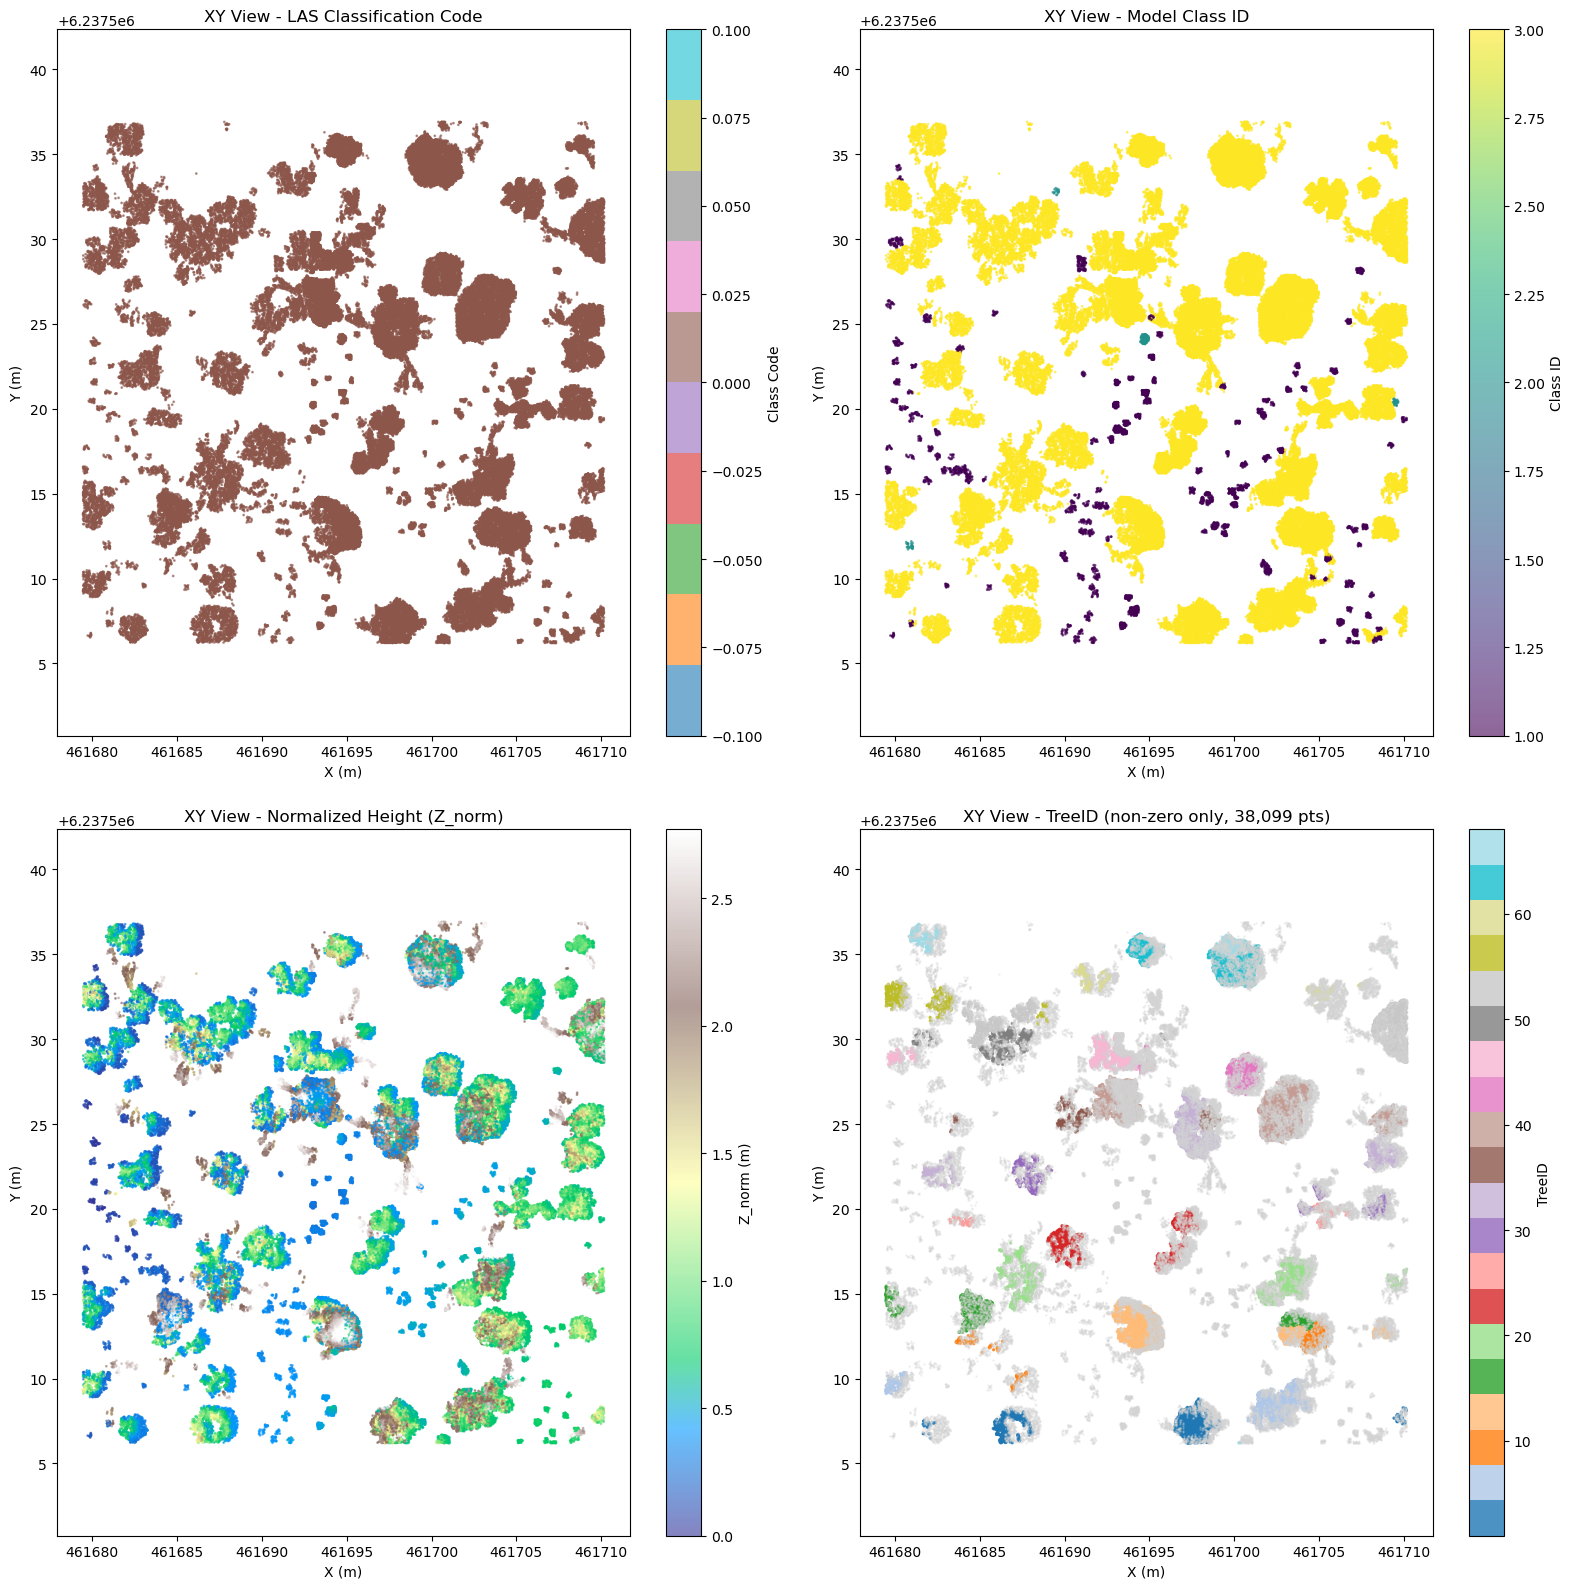

In [ ]:
# Title: Visualize — 2D plots

# Plot 1: XY view colored by LAS classification
if las_files_recon:
    fig, axes = plt.subplots(2, 2, figsize=(16, 16))
    
    # Top-left: XY view by LAS classification
    sc1 = axes[0, 0].scatter(x_plot, y_plot, c=class_plot, s=1, cmap='tab10', alpha=0.6)
    axes[0, 0].set_xlabel('X (m)')
    axes[0, 0].set_ylabel('Y (m)')
    axes[0, 0].set_title('XY View - LAS Classification Code')
    axes[0, 0].set_aspect('equal', adjustable='datalim')
    plt.colorbar(sc1, ax=axes[0, 0], label='Class Code')
    
    # Top-right: XY view by model class ID
    sc2 = axes[0, 1].scatter(x_plot, y_plot, c=classid_plot, s=1, cmap='viridis', alpha=0.6)
    axes[0, 1].set_xlabel('X (m)')
    axes[0, 1].set_ylabel('Y (m)')
    axes[0, 1].set_title('XY View - Model Class ID')
    axes[0, 1].set_aspect('equal', adjustable='datalim')
    plt.colorbar(sc2, ax=axes[0, 1], label='Class ID')
    
    # Bottom-left: XY view by Z_norm (height)
    sc3 = axes[1, 0].scatter(x_plot, y_plot, c=znorm_plot, s=1, cmap='terrain', alpha=0.6, vmin=0, vmax=np.percentile(znorm_plot, 95))
    axes[1, 0].set_xlabel('X (m)')
    axes[1, 0].set_ylabel('Y (m)')
    axes[1, 0].set_title('XY View - Normalized Height (Z_norm)')
    axes[1, 0].set_aspect('equal', adjustable='datalim')
    plt.colorbar(sc3, ax=axes[1, 0], label='Z_norm (m)')
    
    # Bottom-right: XY view by treeID
    tree_mask = tree_plot > 0
    if tree_mask.any():
        sc4 = axes[1, 1].scatter(x_plot[tree_mask], y_plot[tree_mask], c=tree_plot[tree_mask], 
                                  s=2, cmap='tab20', alpha=0.8)
        axes[1, 1].scatter(x_plot[~tree_mask], y_plot[~tree_mask], c='lightgray', s=0.5, alpha=0.3)
        axes[1, 1].set_xlabel('X (m)')
        axes[1, 1].set_ylabel('Y (m)')
        axes[1, 1].set_title(f'XY View - TreeID (non-zero only, {tree_mask.sum():,} pts)')
        axes[1, 1].set_aspect('equal', adjustable='datalim')
        plt.colorbar(sc4, ax=axes[1, 1], label='TreeID')
    else:
        axes[1, 1].text(0.5, 0.5, 'No treeID data', ha='center', va='center', transform=axes[1, 1].transAxes)
        axes[1, 1].set_title('XY View - TreeID (none found)')
    
    plt.tight_layout()
    plt.show()

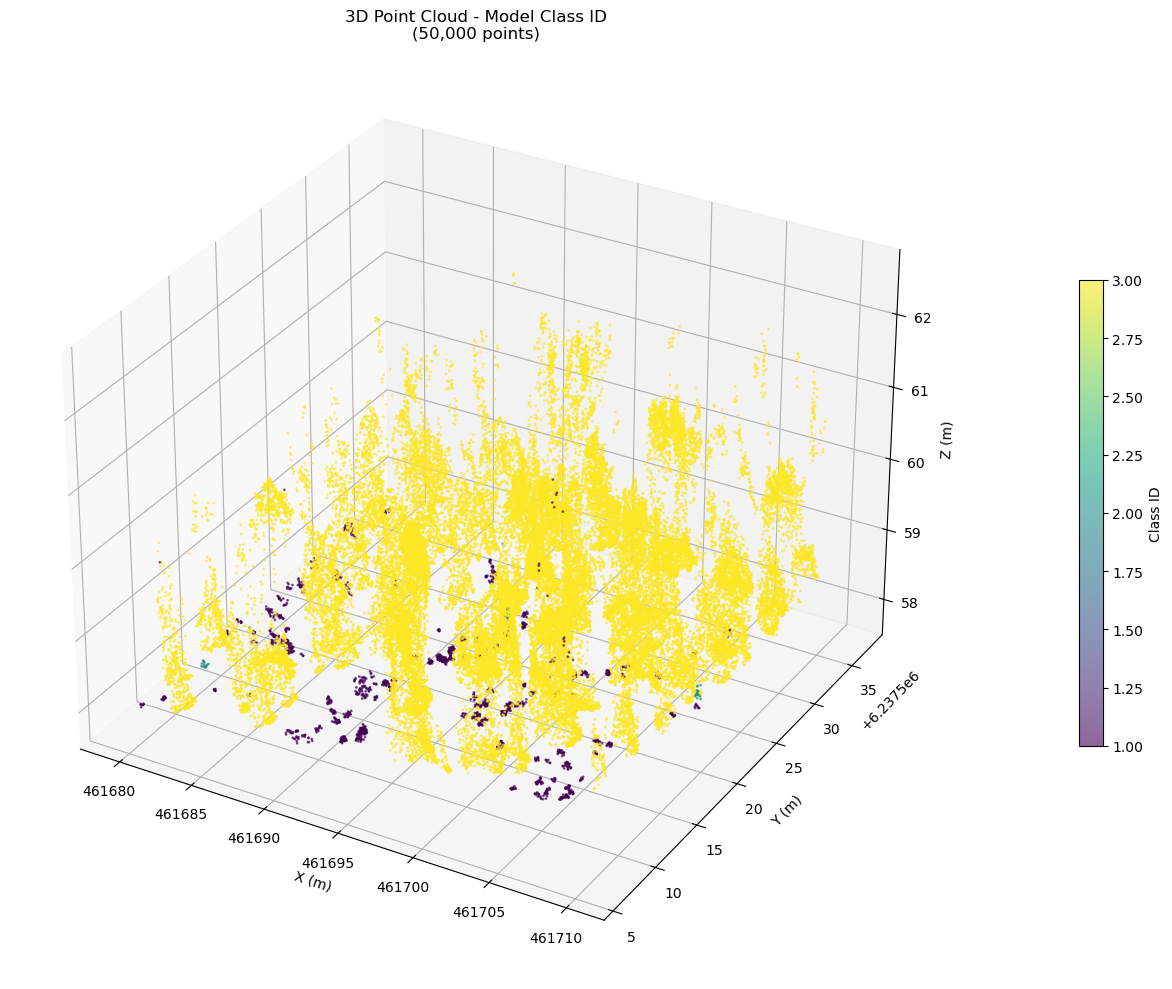


💡 Class mapping:
   LAS 64 → Model ID 0 (Forb)
   LAS 65 → Model ID 1 (Woody debris)
   LAS 66 → Model ID 2 (Hummock)
   LAS 67 → Model ID 3 (Shrub)
   LAS 68 → Model ID 4 (Mallee)


In [ ]:
# Title: Visualize — 3D plot & class mapping

# Processing parameters
VOXEL_SIZE = 0.10  # 10 cm voxels
IGNORE_INDEX = -100  # PyTorch convention for ignored labels

# Class mapping: LAS classification codes -> model class IDs
CLASS_REMAP = {
    64: 0,  # Forb
    65: 1,  # Woody debris
    66: 2,  # Hummock
    67: 3,  # Shrub
    68: 4,  # Mallee
    0: IGNORE_INDEX,  # Unmatched / background
}

# Plot 2: 3D scatter plot colored by classification
if las_files_recon:
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(14, 10))
    
    # 3D view colored by model class ID
    ax = fig.add_subplot(111, projection='3d')
    
    # Further subsample for 3D plot (slower rendering)
    max_3d_points = 50000
    if len(x_plot) > max_3d_points:
        idx_3d = np.random.choice(len(x_plot), max_3d_points, replace=False)
        x_3d = x_plot[idx_3d]
        y_3d = y_plot[idx_3d]
        z_3d = z_plot[idx_3d]
        c_3d = classid_plot[idx_3d]
    else:
        x_3d, y_3d, z_3d = x_plot, y_plot, z_plot
        c_3d = classid_plot
    
    scatter = ax.scatter(x_3d, y_3d, z_3d, c=c_3d, s=1, cmap='viridis', alpha=0.6)
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.set_zlabel('Z (m)')
    ax.set_title(f'3D Point Cloud - Model Class ID\n({len(x_3d):,} points)')
    plt.colorbar(scatter, ax=ax, label='Class ID', shrink=0.5, pad=0.1)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n💡 Class mapping:")
    for las_code, model_id in CLASS_REMAP.items():
        if model_id != IGNORE_INDEX:
            class_names = {0: 'Forb', 1: 'Woody debris', 2: 'Hummock', 3: 'Shrub', 4: 'Mallee'}
            print(f"   LAS {las_code} → Model ID {model_id} ({class_names.get(model_id, 'Unknown')})")


TreeID statistics:
  Unique trees: 67
  Total tree points: 38,099
  Points per tree (mean): 568.6
  Points per tree (median): 274.0
  Points per tree (min/max): 3/4705


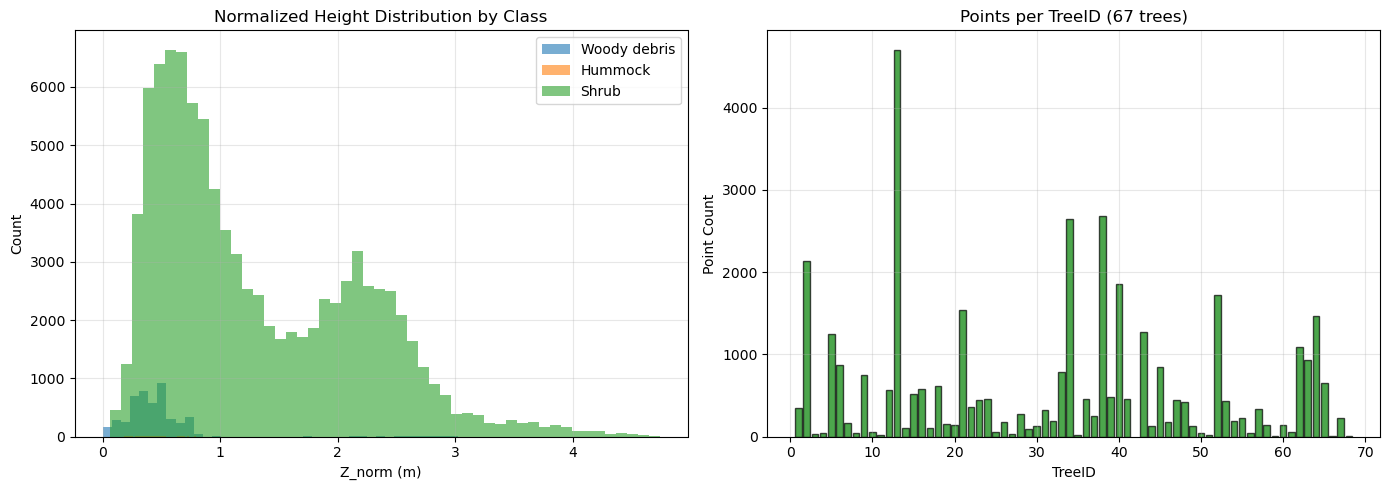

In [ ]:
# Title: Visualize — Height profiles

# Plot 3: Height profiles by class
if las_files_recon:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Left: Z_norm histogram by class
    class_names = {0: 'Forb', 1: 'Woody debris', 2: 'Hummock', 3: 'Shrub', 4: 'Mallee', IGNORE_INDEX: 'IGNORE'}
    
    for cls_id in sorted(np.unique(classid_plot)):
        if cls_id == IGNORE_INDEX:
            continue
        mask = classid_plot == cls_id
        if mask.sum() > 0:
            axes[0].hist(znorm_plot[mask], bins=50, alpha=0.6, label=f'{class_names.get(cls_id, cls_id)}')
    
    axes[0].set_xlabel('Z_norm (m)')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Normalized Height Distribution by Class')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Right: TreeID histogram
    tree_nonzero = tree_plot[tree_plot > 0]
    if len(tree_nonzero) > 0:
        unique_trees, counts = np.unique(tree_nonzero, return_counts=True)
        axes[1].bar(unique_trees, counts, color='green', edgecolor='black', alpha=0.7)
        axes[1].set_xlabel('TreeID')
        axes[1].set_ylabel('Point Count')
        axes[1].set_title(f'Points per TreeID ({len(unique_trees)} trees)')
        axes[1].grid(True, alpha=0.3)
        
        print(f"\nTreeID statistics:")
        print(f"  Unique trees: {len(unique_trees)}")
        print(f"  Total tree points: {len(tree_nonzero):,}")
        print(f"  Points per tree (mean): {counts.mean():.1f}")
        print(f"  Points per tree (median): {np.median(counts):.1f}")
        print(f"  Points per tree (min/max): {counts.min()}/{counts.max()}")
    else:
        axes[1].text(0.5, 0.5, 'No treeID data', ha='center', va='center', transform=axes[1].transAxes)
        axes[1].set_title('TreeID Distribution (none found)')
    
    plt.tight_layout()
    plt.show()